In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib; matplotlib.rcParams.update({'font.size': 18})
pd.set_option('display.max_columns', 9)
import warnings; warnings.filterwarnings("ignore")
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression

In [2]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import course_helpers as chh
apply_beamer_theme(
    "madrid", skip_font_download=True, author="Robert Pettis", date="Fall 2026",
    show_slide_number=True, cell_tags=True, notebook_path="17-Meta-Learners.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 7 cell(s):
 cell_index  slide_id                                  tags
          9 slide-0-5 slide_hide_prompt, slide_remove_input
         11 slide-0-6 slide_hide_prompt, slide_remove_input
         16 slide-1-2 slide_hide_prompt, slide_remove_input
         19 slide-1-3 slide_hide_prompt, slide_remove_input
         28 slide-2-2 slide_hide_prompt, slide_remove_input
         34 slide-2-6 slide_hide_prompt, slide_remove_input
         46 slide-3-8 slide_hide_prompt, slide_remove_input


In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Meta Learners

### Causal Machine Learning

<br>

<b style="color:#73000A;">Robert Pettis</b>
Fall 2026

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Effect Heterogeneity

- Interested in finding <b style="color:#73000A;">treatment effect heterogeneity</b>: how units respond differently to the treatment
- Want to estimate

$$
\tau(x) = E[Y_i(1) - Y_i(0) \mid X] = E[\tau_i \mid X]
$$

- Or $E[\delta Y_i(t) \mid X]$ in the continuous case
- How <b style="color:#73000A;">sensitive</b> the units are to the treatment
- Super useful when we can't treat everyone and need to prioritize the treatment
    - Want to give discounts, but have a limited budget

### Previously

- Transformed the outcome variable $Y$ so we could plug it in a predictive model and get a <b style="color:#73000A;">CATE</b> estimate
- Paid a price in terms of <b style="color:#73000A;">variance increase</b>
- Something we see a lot in Data Science
    - No single best method: each one has its downsides and upsides
    - Worth learning many techniques, so you can trade off one for the other depending on the circumstances
- Today: more tools for you to have at your disposal

### Meta Learners

- A simple way to leverage <b style="color:#73000A;">off-the-shelf predictive machine learning</b> methods to estimate the CATE
- None of them is the single best one; each has its weakness
- Highly dependent on the context
- Deploy predictive ML models: linear regression, boosted decision trees, neural networks, gaussian processes
- Success also highly dependent on what machine learning method it uses as its <b style="color:#73000A;">components</b>
- Oftentimes you just have to try out many different things and see what works best

### The Data

- Same data as before: <b style="color:#73000A;">investment advertisement emails</b>
- Goal: figure out who will respond better to the email
- A little twist
    - <b style="color:#73000A;">Non-random</b> data to train the models
    - <b style="color:#73000A;">Random</b> data to validate them
- Non-random data is a much harder task: the meta learners need to <b style="color:#73000A;">debias the data</b> **AND** estimate the CATE

In [4]:
test = pd.read_csv("data/invest_email_rnd.csv")
train = pd.read_csv("data/invest_email_biased.csv")
train.head()

,age,income,insurance,invested,em1,em2,em3,converted
0,44.1,5483.80,6155.29,14294.81,0,0,1,0
1,39.8,2737.92,50069.40,7468.15,1,0,0,0
2,49.0,2712.51,5707.08,5095.65,0,0,1,1
3,39.7,2326.37,15657.97,6345.20,0,0,0,0
4,35.3,2787.26,27074.44,14114.86,1,1,0,0


### Outcome, Treatment, Features

- Outcome variable: <b style="color:#73000A;">conversion</b>
- Treatment: <b style="color:#73000A;">email-1</b>
- Features $X$ to search for heterogeneity in the treatment effect

```python
y = "converted"
T = "em1"
X = ["age", "income", "insurance", "invested"]
```

In [5]:
y = "converted"
T = "em1"
X = ["age", "income", "insurance", "invested"]


def elast(data, y, t):
    return (np.sum((data[t] - data[t].mean()) * (data[y] - data[y].mean())) /
            np.sum((data[t] - data[t].mean()) ** 2))


def cumulative_gain(dataset, prediction, y, t, min_periods=30, steps=100):
    # normalized: the baseline (ATE times the share of the sample) is subtracted,
    # so a random ordering sits at zero
    size = dataset.shape[0]
    ordered_df = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    ate = elast(dataset, y, t)
    return np.array([(elast(ordered_df.head(rows), y, t) - ate) * (rows / size) for rows in n_rows])


def gain_plot(test_df, train_df, title):
    gain_curve_test = cumulative_gain(test_df, "cate", y="converted", t="em1")
    gain_curve_train = cumulative_gain(train_df, "cate", y="converted", t="em1")
    pct = np.linspace(0, 100, len(gain_curve_test))
    use_plotplainblind()
    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.plot(pct, gain_curve_test, color="C0", lw=2.5,
            label="Test (AUC %.2f)" % np.nansum(gain_curve_test))
    ax.plot(pct, gain_curve_train, color="C1", lw=2.5,
            label="Train (AUC %.2f)" % np.nansum(gain_curve_train))
    ax.axhline(0, linestyle=":", color="black", lw=1.5, label="Baseline")
    ax.set_xlabel("% of sample, ranked by predicted CATE")
    set_top_ylabel(ax, "Normalized cumulative gain")
    ax.set_title(title)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

In [6]:
# Shorthand used by the compact versions below (skip cells, not in the slideshow)
def boost(**kw):
    return HistGradientBoostingRegressor(early_stopping=False, random_state=0, **kw)

## S-Learner (aka, the Go-Horse Learner)

- The <b style="color:#73000A;">simplest</b> learner
- A good first 
- A single (hence the S) machine learning model $M_s$ to estimate

$$
\mu(x) = E[Y \mid T, X]
$$

- Simply include the <b style="color:#73000A;">treatment as a feature</b> in the model that tries to predict the outcome $Y$
- Note: a regression tree here, but since the outcome is binary you could also use a classifier
    - Adapt the code so the model outputs probabilities instead of the binary class, 0, 1

### The S-Learner in a Diagram

- Predictions under <b style="color:#73000A;">different treatment regimes</b>
- The difference in predictions between the test and control is our CATE estimate

$$
\hat{\tau}(x)_i = M_s(X_i, T=1) - M_s(X_i, T=0)
$$

<div style="text-align:center;"><img src="images/facure-meta/s-learner.png" width="560"></div>

### The S-Learner in Code

```python
from sklearn.ensemble import HistGradientBoostingRegressor

s_learner = HistGradientBoostingRegressor(max_depth=3, min_samples_leaf=30,
                                          early_stopping=False, random_state=0)
s_learner.fit(train[X + [T]], train[y])

s_learner_cate_train = (s_learner.predict(train[X].assign(em1=1)) -
                        s_learner.predict(train[X].assign(em1=0)))

s_learner_cate_test = test.assign(
    cate=(s_learner.predict(test[X].assign(em1=1)) -
          s_learner.predict(test[X].assign(em1=0))))
```

- Gradient boosted trees, three levels deep, at least 30 customers in every leaf, features $X$ <b style="color:#73000A;">plus the treatment</b>
- Then predict with the email column set to 1 for everyone, again with it set to 0; the difference is the CATE estimate

In [7]:
np.random.seed(123)
s_learner = HistGradientBoostingRegressor(max_depth=3, min_samples_leaf=30,
                                          early_stopping=False, random_state=0)
s_learner.fit(train[X + [T]], train[y])

s_learner_cate_train = (s_learner.predict(train[X].assign(em1=1)) -
                        s_learner.predict(train[X].assign(em1=0)))

s_learner_cate_test = test.assign(
    cate=(s_learner.predict(test[X].assign(em1=1)) -
          s_learner.predict(test[X].assign(em1=0))))

In [8]:
# Compact version of the S-learner cell above, same result
s_learner = boost(max_depth=3, min_samples_leaf=30).fit(train[X + [T]], train[y])
s_learner_cate_train = (s_learner.predict(train[X].assign(**{T: 1})) -
                        s_learner.predict(train[X].assign(**{T: 0})))
s_learner_cate_test = test.assign(cate=s_learner.predict(test[X].assign(**{T: 1})) -
                                       s_learner.predict(test[X].assign(**{T: 0})))

### Evaluating the S-Learner

- The <b style="color:#73000A;">cumulative gain curve</b> in the test set
- Also the gain curve in the train
    - The train is biased, so that curve cannot tell if the model is good
    - It can point out <b style="color:#73000A;">overfitting</b> to the training set: the curve in the train will be super high
    - To see what that looks like, replace `max_depth` from 3 to 20
- Curves are normalized: the baseline is subtracted, so a random ordering sits at zero

```python
gain_curve_test = cumulative_gain(s_learner_cate_test, "cate",
                                  y="converted", t="em1")
gain_curve_train = cumulative_gain(train.assign(cate=s_learner_cate_train), "cate",
                                   y="converted", t="em1")
plt.plot(gain_curve_test, label="Test")
plt.plot(gain_curve_train, label="Train")
plt.axhline(0, linestyle=":", color="black", label="Baseline")
```

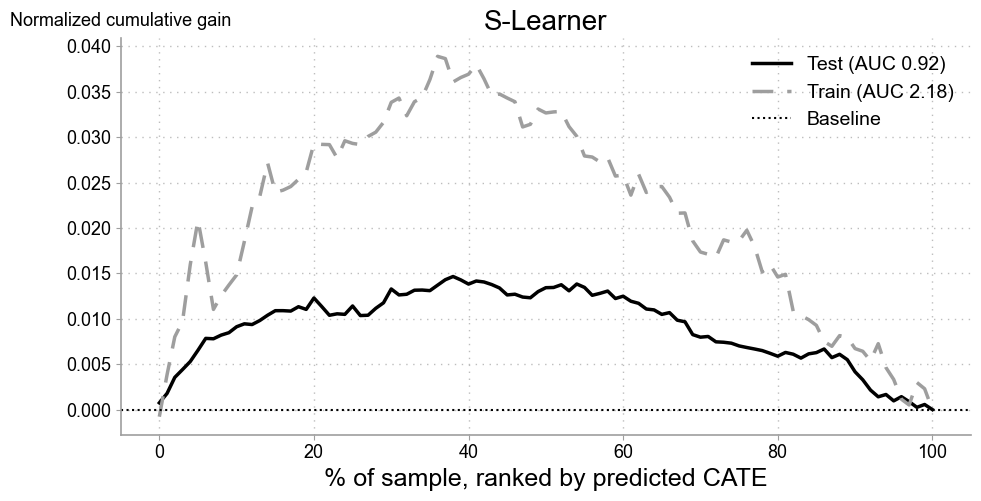

In [9]:
gain_plot(s_learner_cate_test, train.assign(cate=s_learner_cate_train), "S-Learner")

### Not Great, Not Terrible

- Although simple, the S-learner performs <b style="color:#73000A;">okay</b> on this dataset
- Depending on the type of data, the S-learner might do better or worse
- Handles both <b style="color:#73000A;">continuous and discrete</b> treatments
    - The rest of the learners today can only deal with discrete treatments

### The Major Disadvantage

- Tends to <b style="color:#73000A;">bias the treatment effect towards zero</b>
- Employs what is usually a regularized machine learning model
    - That regularization can restrict the estimated treatment effect
    - For example: If other covariates predict outcome better than treatment, trees might not even split on treatment...
- Chernozhukov et al (2016) outline this problem using simulated data

### Chernozhukov's Simulation

<div style="text-align:center;"><img src="images/facure-meta/zero-bias-s-learner.png" width="380"></div>

- The difference between the true causal effect (red outline) and the estimated causal effect, $\tau - \hat{\tau}$, using an S-learner
- The estimated causal effect is <b style="color:#73000A;">heavily biased</b>

### Even Worse

- If the treatment is <b style="color:#73000A;">very weak</b> relative to the impact other covariates play in explaining the outcome, the S-learner can <b style="color:#73000A;">discard the treatment variable completely</b>
- Highly related to the chosen ML model
    - The greater the regularization, the greater the problem

### Another Example: Different Fits for Treatment and Control

![S-learner response functions](https://matteocourthoud.github.io/post/meta_learners/img/meta_learners_25_0.png)

- Model is flexible enough to understand there is a difference in levels between treatment and control
- It fits the **control response**, $\hat{\mu}(x,0)$, well, but the **treated response**, $\hat{\mu}(x,1)$, less accurately.
- Errors in either curve affect the estimated CATE: $\hat{\tau}(x)=\hat{\mu}(x,1)-\hat{\mu}(x,0)$.

## T-Learner
- A good first model to try with categorical treatment
- Solves the problem of discarding the treatment entirely by <b style="color:#73000A;">forcing the learner to first split on it</b>
- Instead of a single model, <b style="color:#73000A;">one model per treatment variable</b>
- Binary case: only two models to estimate (hence the name T)

$$
\mu_0(x) = E[Y \mid T=0, X]
$$

$$
\mu_1(x) = E[Y \mid T=1, X]
$$

- At prediction time, counterfactual predictions for each treatment

$$
\hat{\tau}(x)_i = M_1(X_i) - M_0(X_i)
$$

### The T-Learner in a Diagram

<div style="text-align:center;"><img src="images/facure-meta/t-learner.png" width="640"></div>

### The T-Learner in Code

```python
m0 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=60,
                                   early_stopping=False, random_state=0)
m1 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=60,
                                   early_stopping=False, random_state=0)

m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])

# estimate the CATE
t_learner_cate_train = m1.predict(train[X]) - m0.predict(train[X])
t_learner_cate_test = test.assign(
    cate=m1.predict(test[X]) - m0.predict(test[X]))
```

- One model on the untreated rows, one on the treated rows, then subtract

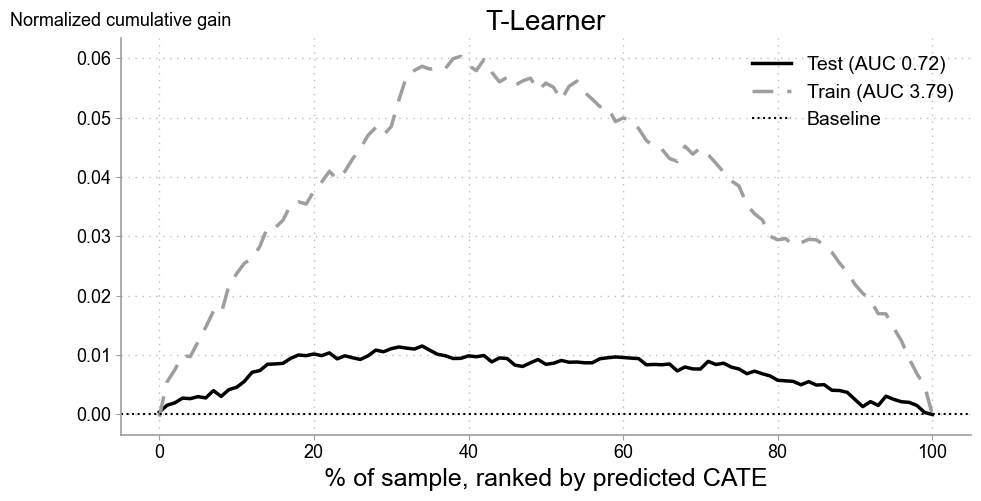

In [10]:
np.random.seed(123)

m0 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=60,
                                   early_stopping=False, random_state=0)
m1 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=60,
                                   early_stopping=False, random_state=0)

m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])

# estimate the CATE
t_learner_cate_train = m1.predict(train[X]) - m0.predict(train[X])
t_learner_cate_test = test.assign(cate=m1.predict(test[X]) - m0.predict(test[X]))

gain_plot(t_learner_cate_test, train.assign(cate=t_learner_cate_train), "T-Learner")

In [11]:
# Compact version of the T-learner cell above, same result
m0 = boost(max_depth=2, min_samples_leaf=60).fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1 = boost(max_depth=2, min_samples_leaf=60).fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])
t_learner_cate_train = m1.predict(train[X]) - m0.predict(train[X])
t_learner_cate_test = test.assign(cate=m1.predict(test[X]) - m0.predict(test[X]))

### Also OK on This Dataset

- Test performance doesn't look much different from the S-learner
    - Perhaps because the treatment is not that weak
- Training performance much higher than testing: the model is <b style="color:#73000A;">overfitting</b>
    - Each model is fit on only a <b style="color:#73000A;">subset</b> of the data
    - With less data points, the model is probably learning some noise

### Regularization Bias Again

- Avoids the problem of not picking up on a weak treatment variable, but can still suffer from <b style="color:#73000A;">regularization bias</b>
- A situation from Künzel et al, 2019
    - <b style="color:#73000A;">Lots of data</b> for the untreated, <b style="color:#73000A;">very few</b> for the treated
    - Pretty common in many applications, as treatment is often expensive
- Some <b style="color:#73000A;">non linearity</b> in the outcome $Y$, but the **treatment effect is constant**

### Few Treated, Many Controls

<div style="text-align:center;"><img src="images/facure-meta/t-learner-problem.png" width="900"></div>

### The T-Learner's Effect Curve

- The same situation, simulated: 500 untreated, 50 treated, a bump in $Y$ that both arms share, treatment effect <b style="color:#73000A;">constant at 1</b>
- $M_0$ follows the bump. $M_1$, with 50 points and at least 25 per leaf, is close to flat
- Blue line minus red line: a <b style="color:#73000A;">nonlinear CATE</b>, which is wrong, since the CATE is constant and equal to 1

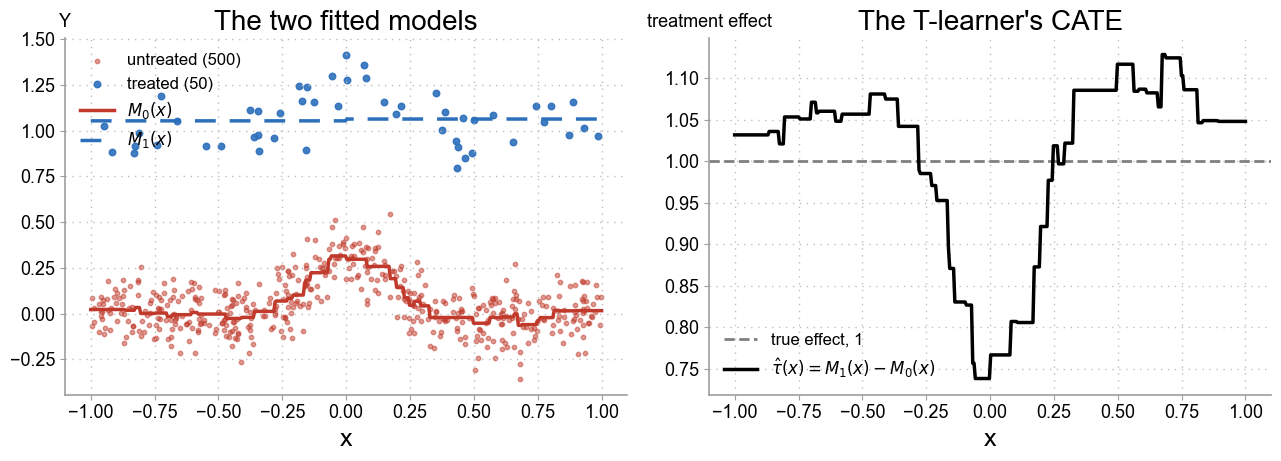

In [12]:
rng = np.random.default_rng(1)
x0 = rng.uniform(-1, 1, 500)
x1 = rng.uniform(-1, 1, 50)
bump = lambda x: 0.3 * np.exp(-x ** 2 / 0.05)
y0 = bump(x0) + rng.normal(0, 0.1, 500)
y1 = bump(x1) + 1 + rng.normal(0, 0.1, 50)          # effect is 1 for everyone

m0_sim = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=25,
                                       early_stopping=False, random_state=0)
m1_sim = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=25,
                                       early_stopping=False, random_state=0)
m0_sim.fit(x0.reshape(-1, 1), y0)
m1_sim.fit(x1.reshape(-1, 1), y1)

grid = np.linspace(-1, 1, 400).reshape(-1, 1)
mu0_hat, mu1_hat = m0_sim.predict(grid), m1_sim.predict(grid)

use_plotplainblind()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(x0, y0, s=10, color="#c0392b", alpha=.5, label="untreated (500)")
axes[0].scatter(x1, y1, s=22, color="#2c6fbb", alpha=.9, label="treated (50)")
axes[0].plot(grid, mu0_hat, color="#c0392b", lw=2.5, label=r"$M_0(x)$")
axes[0].plot(grid, mu1_hat, color="#2c6fbb", lw=2.5, label=r"$M_1(x)$")
axes[0].set_xlabel("x")
set_top_ylabel(axes[0], "Y")
axes[0].set_title("The two fitted models")
axes[0].legend(fontsize=12, loc="upper left")

axes[1].axhline(1, color="grey", lw=2, linestyle="--", label="true effect, 1")
axes[1].plot(grid, mu1_hat - mu0_hat, color="black", lw=2.5, label=r"$\hat{\tau}(x) = M_1(x) - M_0(x)$")
axes[1].set_xlabel("x")
set_top_ylabel(axes[1], "treatment effect")
axes[1].set_title("The T-learner's CATE")
axes[1].legend(fontsize=12, loc="lower left")
plt.tight_layout()
plt.show()

### What Happens

- Very few treated observations: $M_1$ is a <b style="color:#73000A;">very simple</b> model (linear in this case) to avoid overfitting
- $M_0$ is more complicated, but that's OK: the abundance of data prevents overfitting
- All reasonable from a Machine Learning perspective
- But compute $\hat{\tau} = M_1(X) - M_0(X)$
    - Linearity of $M_1(X)$ minus non linearity of $M_0(X)$ gives a <b style="color:#73000A;">nonlinear CATE</b> (blue line minus red line)
    - Wrong: the CATE is constant and equal to 1

### Between a Rock and a Hard Place

- The model for the untreated can pick up the non linearity
- The model for the treated cannot, because of the regularization needed for a small sample size
- Less regularization on that model, and the small sample size will cause you to <b style="color:#73000A;">overfit</b>
- The solution: an <b style="color:#73000A;">X-learner</b>, proposed in the same paper by Künzel et al

## X-Learner

- Significantly more complex to explain than the previous learner, but its <b style="color:#73000A;">implementation is quite simple</b>
- <b style="color:#73000A;">Two stages</b> and a <b style="color:#73000A;">propensity score model</b>
- First stage identical to the T-learner: split the samples into treated and untreated, fit a ML model for each

$$
\hat{M}_0(X) \approx E[Y \mid T=0, X]
$$

$$
\hat{M}_1(X) \approx E[Y \mid T=1, X]
$$

### Second Stage: Impute the Treatment Effect

- For the control and for the treated, using the models above

$$
\hat{\tau}(X, T=0) = \hat{M}_1(X, T=0) - Y_{T=0}
$$

$$
\hat{\tau}(X, T=1) = Y_{T=1} - \hat{M}_0(X, T=1)
$$

- Then two more models to <b style="color:#73000A;">predict those effects</b>

$$
\hat{M}_{\tau 0}(x) \approx E[\hat{\tau}_i \mid X_i = x,\ T_i = 0]
$$

$$
\hat{M}_{\tau 1}(x) \approx E[\hat{\tau}_i \mid X_i = x,\ T_i = 1]
$$

### Reading the Picture

- Red crosses: $\hat{\tau}(X, T=0)$, the imputed treatment effect on the untreated; red dashed line: $\hat{M}_{\tau 0}(X)$
- This model is <b style="color:#73000A;">wrong</b>
    - $\hat{\tau}(X, T=0)$ was made with the regularized, simple model $\hat{M}_1$, estimated on the treated
    - The effect it imputes is non linear, since it **doesn't** capture the non-linearity in $Y$
- Blue dots: $\hat{\tau}(X, T=1)$, the imputed treatment effect for the treated
    - Estimated with the <b style="color:#73000A;">correct</b> model $M_0$, trained in the untreated, large, sample
    - Correct imputed effects, so a correct second stage model $\hat{M}_{\tau 1}(X)$, the blue line

### The Second Stage, Drawn

<div style="text-align:center;"><img src="images/facure-meta/second-stage-x.png" width="900"></div>

### Combining the Two

- One model wrong because we imputed the treatment effects wrongly, another correct because we imputed them correctly
- Need to combine the two giving <b style="color:#73000A;">more weight to the correct model</b>: the propensity score model
- $\hat{e}(x)$ the propensity score model

$$
\hat{\tau}(x) = \hat{M}_{\tau 0}(X)\,\hat{e}(x) + \hat{M}_{\tau 1}(X)\,(1 - \hat{e}(x))
$$

- Very few treated units: $\hat{e}(x)$ is very small, a very small weight on the wrong model $\hat{M}_{\tau 0}(X)$
- $1 - \hat{e}(x)$ close to one: a high weight on the correct model $\hat{M}_{\tau 1}(X)$

### More Generally

- The propensity score weighted average gives more weight to the CATE model estimated where the <b style="color:#73000A;">assigned treatment was more likely</b>
- In other words, favor the model trained using <b style="color:#73000A;">more data</b>

### X-Learner Against T-Learner

<div style="text-align:center;"><img src="images/facure-meta/t-vs-x-learner.png" width="900"></div>

- Compared to the T-learner, the X-learner does a much better job correcting the wrong CATE at the non linearity
- In general performs better when one treatment group is <b style="color:#73000A;">much larger</b> than the other

### The X-Learner in a Diagram

<div style="text-align:center;"><img src="images/facure-meta/x-learner.png" width="820"></div>

### The X-Learner in Code

```python
# first stage, the same as the T-learner, plus a propensity score model
m0 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                   early_stopping=False, random_state=0)
m1 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                   early_stopping=False, random_state=0)
g = LogisticRegression(penalty=None, max_iter=5000)
m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])
g.fit(train[X], train[T])

# impute the treatment effects, then the second stage
d_train = np.where(train[T] == 0, m1.predict(train[X]) - train[y],
                                  train[y] - m0.predict(train[X]))
mx0 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                    early_stopping=False, random_state=0)
mx1 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                    early_stopping=False, random_state=0)
mx0.fit(train.query(f"{T}==0")[X], d_train[train[T] == 0])
mx1.fit(train.query(f"{T}==1")[X], d_train[train[T] == 1])

# corrected predictions, weighted by the propensity score
def ps_predict(df, t):
    return g.predict_proba(df[X])[:, t]

x_cate_test = test.assign(cate=ps_predict(test, 1) * mx0.predict(test[X]) +
                               ps_predict(test, 0) * mx1.predict(test[X]))
```

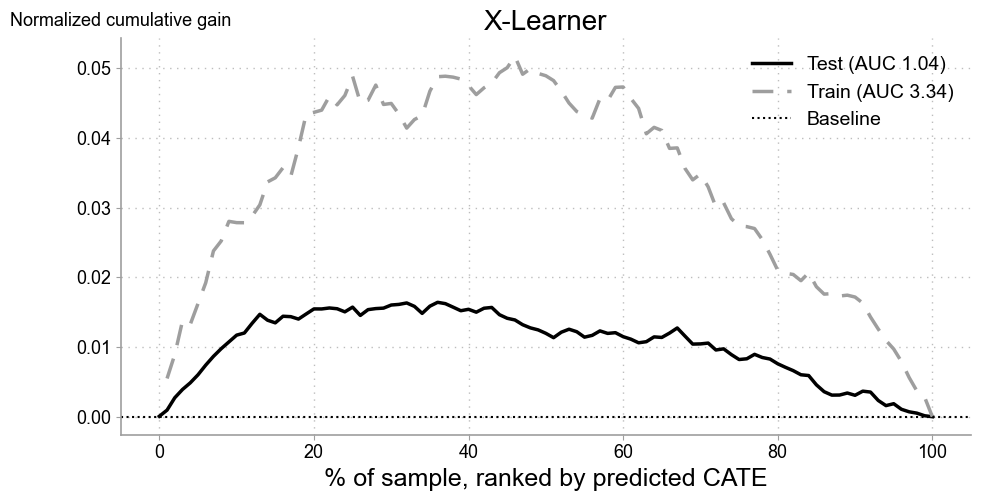

In [13]:
np.random.seed(123)

# first stage models
m0 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                   early_stopping=False, random_state=0)
m1 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                   early_stopping=False, random_state=0)

# propensity score model
g = LogisticRegression(penalty=None, max_iter=5000)

m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])

g.fit(train[X], train[T])

d_train = np.where(train[T] == 0,
                   m1.predict(train[X]) - train[y],
                   train[y] - m0.predict(train[X]))

# second stage
mx0 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                    early_stopping=False, random_state=0)
mx1 = HistGradientBoostingRegressor(max_depth=2, min_samples_leaf=30,
                                    early_stopping=False, random_state=0)

mx0.fit(train.query(f"{T}==0")[X], d_train[train[T] == 0])
mx1.fit(train.query(f"{T}==1")[X], d_train[train[T] == 1])


def ps_predict(df, t):
    return g.predict_proba(df[X])[:, t]


x_cate_train = (ps_predict(train, 1) * mx0.predict(train[X]) +
                ps_predict(train, 0) * mx1.predict(train[X]))

x_cate_test = test.assign(cate=(ps_predict(test, 1) * mx0.predict(test[X]) +
                                ps_predict(test, 0) * mx1.predict(test[X])))

gain_plot(x_cate_test, train.assign(cate=x_cate_train), "X-Learner")

In [14]:
# Compact version of the X-learner cell above, same result
m0 = boost(max_depth=2, min_samples_leaf=30).fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1 = boost(max_depth=2, min_samples_leaf=30).fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y])
g = LogisticRegression(penalty=None, max_iter=5000).fit(train[X], train[T])

d_train = np.where(train[T] == 0, m1.predict(train[X]) - train[y], train[y] - m0.predict(train[X]))
mx0 = boost(max_depth=2, min_samples_leaf=30).fit(train.query(f"{T}==0")[X], d_train[train[T] == 0])
mx1 = boost(max_depth=2, min_samples_leaf=30).fit(train.query(f"{T}==1")[X], d_train[train[T] == 1])

ps = lambda df, t: g.predict_proba(df[X])[:, t]
x_cate_train = ps(train, 1) * mx0.predict(train[X]) + ps(train, 0) * mx1.predict(train[X])
x_cate_test = test.assign(cate=ps(test, 1) * mx0.predict(test[X]) + ps(test, 0) * mx1.predict(test[X]))

### Once More, an OK Performance

- The S, T and X learners seem to perform <b style="color:#73000A;">pretty similarly</b> on this dataset
- Still worth knowing all these meta learners, so you can use whatever works best for you
- Performance is also highly dependent on the <b style="color:#73000A;">base machine learning model</b>
    - Everything here with Gradient Boosted Trees
    - Something else, or the same thing with different hyperparameters, might work better

### Sources

- Matheus Facure, <b style="color:#73000A;">Causal Inference for the Brave and True</b>, chapter 21, Meta Learners: the text, the diagrams, the data, in his order
- Uber's *causalml* library and its documentation on meta learners
- Künzel, Sekhon, Bickel and Yu (2019), *Metalearners for estimating heterogeneous treatment effects using machine learning*, PNAS: the images and concepts
- Chernozhukov et al (2017), *Double/Debiased Machine Learning for Treatment and Causal Parameters*: the S-learner being biased towards zero
- Gradient boosting here is scikit-learn's `HistGradientBoostingRegressor` in place of LightGBM, and the gain curves are normalized

## Key Ideas

- The simplest thing: a single or <b style="color:#73000A;">S-learner</b> with the treatment as a feature
    - Works well when the treatment is not a weak predictor of the outcome
    - Otherwise, biased towards zero, or drops the treatment entirely
- A <b style="color:#73000A;">T-learner</b> forces the learner to pick up the treatment: one Machine Learning model per treatment level
    - Fine when there are enough samples for all treatment levels
    - Fails when one level has a small sample size, forcing a model to be heavily regularized
- An <b style="color:#73000A;">X-learner</b> adds another level of complexity: two fitting stages and a propensity score model to correct mistakes from models estimated with very few data points
- One big problem (except the S-learner): they assume a <b style="color:#73000A;">binary or categorical</b> treatment
- One more general learner we haven't seen yet: the <b style="color:#73000A;">R-learner</b>. Next time